# 1. PSO (Enjambre de Partículas)

Hugo André Meza Fierros - A00841695

Gil Brandon García Contreras - A01254164

Jesús Alejandro Pérez Granados - A01253993

Santiago Hernández Jiménez - A01662307

Luis Santiago Benvenuto Valerdi - A01286400

---

## 1.1 Definición del problema

Una empresa de comercio electrónico desea ampliar su red logística debido al crecimiento de sus ventas en una zona metropolitana. Actualmente cuenta con 100 clientes, distribuidos en diferentes puntos de la ciudad, a quienes debe realizar entregas periódicas. Cada cliente $j$ está caracterizado por tres datos:

$(x_j, y_j, d_j)$

donde $x_j$ y $y_j$ representan sus coordenadas geográficas simplificadas y $d_j$ representa su demanda semanal de productos.

La empresa desea construir un nuevo centro de distribución desde el cual se atenderán los 100 clientes. La ubicación del centro no ha sido determinada y puede establecerse en cualquier punto dentro de la región:

$0 \leq x \leq 100, 0 \leq y \leq 100$

El costo de distribución aumenta conforme se incrementa la distancia entre el centro
de distribución y los clientes. Además, los clientes con mayor demanda generan un mayor número de desplazamientos. Por ello, la empresa busca una ubicación que minimice la distancia total ponderada por la demanda.

Se utiliza la instancia de `PSO.xlsx` que se encuentra en el drive de la clase.

In [40]:
import pandas as pd

df = pd.read_excel('../data/PSO.xlsx')
df

,Cliente,X,Y,Demanda
0,1,12,84,25
1,2,37,65,40
2,3,82,91,18
3,4,56,23,35
4,5,71,48,50
...,...,...,...,...
95,96,99,84,46
96,97,48,47,30
97,98,31,12,38
98,99,86,24,20


## 1.2 Modelo matemático

In [41]:
from docplex.mp.model import Model
import time

# Conjunto de clientes M = {1, 2, ..., 100}
M = range(1, len(df) + 1)

# Diccionarios mapeados a los índices 1..100
x = dict(enumerate(df['X'], start=1))
y = dict(enumerate(df['Y'], start=1))
d = dict(enumerate(df['Demanda'], start=1))

# --- 1. Inicializar el Modelo de DOcplex ---

start_time = time.time()
mdl = Model(name="Localizacion_CD_Manhattan")

# --- 2. Variables de Decisión ---
# Variables continuas simples para la ubicación del CD (entre 0 y 100)
X = mdl.continuous_var(lb=0, ub=100, name="X")
Y = mdl.continuous_var(lb=0, ub=100, name="Y")

# Variables auxiliares u_i y v_i con las mismas llaves del conjunto M (1..100)
u = mdl.continuous_var_dict(M, lb=0, name="u")
v = mdl.continuous_var_dict(M, lb=0, name="v")

# --- 3. Función Objetivo ---
# Minimizar la suma de distancias rectilíneas ponderadas por la demanda
mdl.minimize(mdl.sum(d[i] * (u[i] + v[i]) for i in M))

# --- 4. Restricciones de Linealización Manhattan ---
for i in M:
    # Linealización del valor absoluto para el eje X: u_i >= |X - x_i|
    mdl.add_constraint(u[i] >= X - x[i], ctname=f"manhattan_x1_{i}")
    mdl.add_constraint(u[i] >= x[i] - X, ctname=f"manhattan_x2_{i}")
    
    # Linealización del valor absoluto para el eje Y: v_i >= |Y - y_i|
    mdl.add_constraint(v[i] >= Y - y[i], ctname=f"manhattan_y1_{i}")
    mdl.add_constraint(v[i] >= y[i] - Y, ctname=f"manhattan_y2_{i}")

# --- 5. Resolver el Modelo ---
solucion = mdl.solve(log_output=False)
tiempo_exacto = time.time() - start_time

In [42]:
import numpy as np
# Recopilar métricas del Método Exacto
opt_x = X.solution_value
opt_y = Y.solution_value
opt_fo = mdl.objective_value

# Calcular estadísticas de distancias individuales cliente-CD
distancias_ind = [abs(opt_x - x[i]) + abs(opt_y - y[i]) for i in M]
dist_prom = np.mean(distancias_ind)
dist_max = np.max(distancias_ind)

# --- 3. Crear Estructura de Comparación ---
métricas = {
    'Método': ['Exacto (DOcplex/CPLEX)'],
    'X_CD': [round(opt_x, 4)],
    'Y_CD': [round(opt_y, 4)],
    'Costo_Total_FO': [round(opt_fo, 2)],
    'Tiempo_Segundos': [round(tiempo_exacto, 5)],
    'Gap_Optimidad (%)': [0.0],  # El método exacto es la referencia (0%)
    'Dist_Prom_Cliente': [round(dist_prom, 2)],
    'Dist_Max_Cliente': [round(dist_max, 2)]
}

df_comparativa = pd.DataFrame(métricas)

In [43]:
if solucion:
    print("=" * 40)
    print("SOLUCIÓN ÓPTIMA ENCONTRADA")
    print("=" * 40)
    print(f"Ubicación del Centro de Distribución:")
    print(f"  X* = {X.solution_value:.2f}")
    print(f"  Y* = {Y.solution_value:.2f}")
    print(f"\nCosto Total Ponderado Mínimo: {mdl.objective_value:,.2f}")
    print(f"\nTiempo de cómputo: {tiempo_exacto:.2f}")
else:
    print("No se encontró solución viable.")

SOLUCIÓN ÓPTIMA ENCONTRADA
Ubicación del Centro de Distribución:
  X* = 54.00
  Y* = 55.00

Costo Total Ponderado Mínimo: 147,880.00

Tiempo de cómputo: 0.06


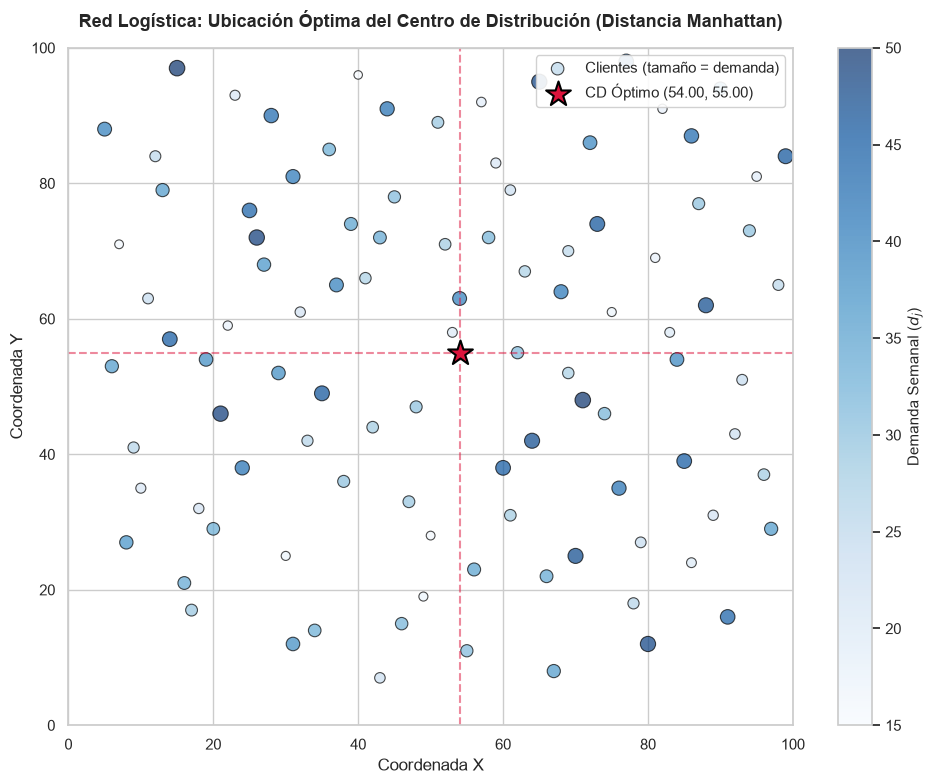

<Figure size 640x480 with 0 Axes>

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))

# 1. Graficar los 100 clientes
# 's' escala el tamaño del punto según la demanda del cliente
scatter = plt.scatter(
    df['X'], 
    df['Y'], 
    s=df['Demanda'] * 2.5, 
    c=df['Demanda'], 
    cmap='Blues', 
    alpha=0.7, 
    edgecolors='black', 
    linewidth=0.8,
    label='Clientes (tamaño = demanda)'
)

# Añadir barra de color para la demanda
cbar = plt.colorbar(scatter)
cbar.set_label('Demanda Semanal ($d_j$)', fontsize=11)

# 2. Obtener las coordenadas óptimas resueltas por DOcplex
x_opt = X.solution_value
y_opt = Y.solution_value

# 3. Graficar el Centro de Distribución Óptimo
plt.scatter(
    x_opt, 
    y_opt, 
    color='crimson', 
    s=350, 
    marker='*', 
    edgecolors='black', 
    linewidth=1.5,
    zorder=5, 
    label=f'CD Óptimo ({x_opt:.2f}, {y_opt:.2f})'
)

# 4. Líneas guía hacia las coordenadas óptimas
plt.axvline(x=x_opt, color='crimson', linestyle='--', alpha=0.5)
plt.axhline(y=y_opt, color='crimson', linestyle='--', alpha=0.5)

# Configuración de límites y etiquetas del mapa
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel('Coordenada X', fontsize=12)
plt.ylabel('Coordenada Y', fontsize=12)
plt.title('Red Logística: Ubicación Óptima del Centro de Distribución (Distancia Manhattan)', fontsize=13, fontweight='bold', pad=15)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()
plt.savefig("../images/pso/mip_ubicacion.png", dpi=300, bbox_inches="tight")

In [45]:
print("Estado del solver:", mdl.solve_details.status)
t_mip_solve = mdl.solve_details.time          # solo resolución
print(f"Tiempo total (con construcción): {tiempo_exacto:.4f} s | solo solve: {t_mip_solve:.4f} s")

Estado del solver: optimal
Tiempo total (con construcción): 0.0570 s | solo solve: 0.0150 s


## 1.3 PSO

Criterio de paro: max 200 iteraciones o 50 sin mejora (tol 1e-6) | óptimo MIP = 147,880
  w  c1  c2   Mejor Z   Z prom.  Desv. est.    Peor Z  Gap mejor (%)  Gap prom. (%)  Gap peor (%)  Éxito (%)  Iter. ejecutadas  Iter. convergencia  % paro por paciencia  Tiempo prom. (s)    X*    Y*
0.5 1.5 1.5 1.479e+05 1.479e+05   4.894e-11 1.479e+05              0              0      9.84e-14        100             115.3               40.53                   100          0.003702    54    55
0.5 1.5   2 1.479e+05 1.479e+05   4.237e-10 1.479e+05              0      1.181e-13     1.555e-12        100             127.8               47.17                   100          0.003896    54    55
0.5   2 1.5 1.479e+05 1.479e+05   6.604e-10 1.479e+05              0      2.165e-13      1.87e-12        100             126.2               45.43                   100          0.003983    54    55
0.5   2   2 1.479e+05 1.479e+05   7.217e-09 1.479e+05      5.904e-14      2.814e-12      1.99e-11        100        

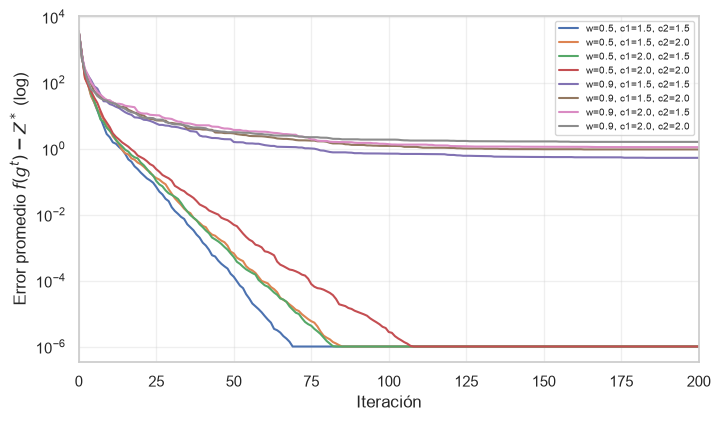

In [46]:
import numpy as np, pandas as pd, time, itertools
import matplotlib.pyplot as plt

xs = df['X'].values.astype(float)
ys = df['Y'].values.astype(float)
ds = df['Demanda'].values.astype(float)
z_opt = mdl.objective_value

def fitness(pos, xs=xs, ys=ys, ds=ds):
    dx = np.abs(pos[:, [0]] - xs[None, :])
    dy = np.abs(pos[:, [1]] - ys[None, :])
    return ((dx + dy) * ds[None, :]).sum(axis=1)

def pso(w, c1, c2, n=30, max_iter=200, patience=50, tol=1e-6, vmax=20, seed=None):
    rng = np.random.default_rng(seed)
    pos = rng.uniform(0, 100, (n, 2))
    vel = rng.uniform(-vmax, vmax, (n, 2))
    f = fitness(pos)
    pbest, pbest_f = pos.copy(), f.copy()
    g = pbest[np.argmin(pbest_f)].copy()
    g_f = pbest_f.min()
    hist, sin_mejora, motivo = [g_f], 0, "max_iter"

    t0 = time.perf_counter()
    for it in range(1, max_iter + 1):
        r1, r2 = rng.random((n, 2)), rng.random((n, 2))
        vel = np.clip(w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (g - pos), -vmax, vmax)
        pos = np.clip(pos + vel, 0, 100)

        f = fitness(pos)
        mejora = f < pbest_f
        pbest[mejora], pbest_f[mejora] = pos[mejora], f[mejora]

        if pbest_f.min() < g_f - tol:
            sin_mejora = 0
        else:
            sin_mejora += 1
        if pbest_f.min() < g_f:
            g_f = pbest_f.min()
            g = pbest[np.argmin(pbest_f)].copy()
        hist.append(g_f)

        if sin_mejora >= patience:
            motivo = "paciencia"
            break
    t = time.perf_counter() - t0
    h = np.array(hist)
    it_conv = int(np.argmax(h <= g_f + 1e-3))     # primera iteración con el valor final (±0.001)
    return g, g_f, it, it_conv, motivo, t, h

W, C1, C2 = [0.5, 0.9], [1.5, 2.0], [1.5, 2.0]
N_RUNS, MAX_IT = 30, 200
filas, hist_all = [], {}

for w, c1, c2 in itertools.product(W, C1, C2):
    zs, its, itc, tiempos, sols, hs, motivos = [], [], [], [], [], [], []
    for s in range(N_RUNS):
        g, gf, it, ic, mot, t, h = pso(w, c1, c2, max_iter=MAX_IT, seed=s)
        zs.append(gf); its.append(it); itc.append(ic); tiempos.append(t)
        sols.append(g); motivos.append(mot)
        hs.append(np.pad(h, (0, MAX_IT + 1 - len(h)), mode="edge"))
    zs = np.array(zs); mejor = int(np.argmin(zs))
    gap = lambda z: max(0.0, (z - z_opt) / z_opt * 100)
    filas.append({
        "w": w, "c1": c1, "c2": c2,
        "Mejor Z": zs.min(), "Z prom.": zs.mean(), "Desv. est.": zs.std(ddof=1), "Peor Z": zs.max(),
        "Gap mejor (%)": gap(zs.min()), "Gap prom. (%)": gap(zs.mean()), "Gap peor (%)": gap(zs.max()),
        "Éxito (%)": 100 * np.mean(zs - z_opt < 1.0),        # corridas a menos de 1 unidad del óptimo
        "Iter. ejecutadas": np.mean(its), "Iter. convergencia": np.mean(itc),
        "% paro por paciencia": 100 * np.mean([m == "paciencia" for m in motivos]),
        "Tiempo prom. (s)": np.mean(tiempos),
        "X*": sols[mejor][0], "Y*": sols[mejor][1],
    })
    hist_all[(w, c1, c2)] = np.array(hs)

df_pso = pd.DataFrame(filas)
print(f"Criterio de paro: max {MAX_IT} iteraciones o 50 sin mejora (tol 1e-6) | óptimo MIP = {z_opt:,.0f}")
with pd.option_context("display.float_format", "{:.4g}".format):
    print(df_pso.to_string(index=False))

# ---------- Convergencia: error promedio de las 30 corridas, escala log ----------
fig, ax = plt.subplots(figsize=(8, 4.5))
for (w, c1, c2), H in hist_all.items():
    err = np.maximum((H - z_opt).mean(axis=0), 1e-6)
    ax.semilogy(err, label=f"w={w}, c1={c1}, c2={c2}")
ax.set_xlabel("Iteración"); ax.set_ylabel(r"Error promedio $f(g^t)-Z^*$ (log)")
ax.set_xlim(0, MAX_IT); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=7)
plt.savefig("../images/pso/convergencia.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- Boxplot de Z final por configuración (opcional, buen respaldo visual) ----------
# (se necesitan los Z de cada corrida: guarda zs por config si lo quieren)

# ---------- Tabla lista para LaTeX ----------
tabla = df_pso[["w","c1","c2","Mejor Z","Z prom.","Desv. est.","Peor Z","Éxito (%)","Iter. convergencia","Tiempo prom. (s)"]]